<a href="https://colab.research.google.com/github/Janith303/Sinhala-and-Maths-Model-training-/blob/MobileNetV2/notebooks/MobileNetV2_letters_10class.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# MobileNetV2 for Sinhala letters (10 classes: letter + correct / wrong)

This notebook is your ResNet50 / DenseNet121 notebook with **MobileNetV2** instead, so the models can be compared fairly. MobileNetV2 is small and fast, which suits a phone app.

**Before you run it**
1. Runtime -> Change runtime type -> **T4 GPU**.
2. Run the cells from top to bottom.
3. By default it uses **the same train / validation / test split** that your ResNet50 notebook saved (`REUSE_SPLIT = True`), so all models are tested on exactly the same images.

**What is different**
- The model is MobileNetV2, with its **own** image scaling (`mobilenet_v2.preprocess_input`, values from -1 to 1). Using another model's scaling would give wrong results.
- **The training curves now also have a TEST line** (next to train and validation). The test score is calculated after every epoch **only to draw the curve**. Early stopping, the best epoch and the learning rate still use the **validation** set only. Do not choose epochs or settings by looking at the test curve, or the test result stops being an honest final check.
- Optional automatic tuning (`RUN_TUNING`), off by default.
- A last section that compares **all models you have trained** in one table.
- Files are saved with the name `mobilenetv2_...`, so your other models are not overwritten.

In [1]:
import os
import sys
import json
import hashlib
import time
import random
import platform
import shutil
import subprocess
import gc

import numpy as np
import pandas as pd
import tensorflow as tf
import keras
import sklearn
import kagglehub
import matplotlib
import matplotlib.pyplot as plt

# Architecture-specific preprocessor for MobileNetV2 (it scales pixels differently from ResNet50)
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input as mobilenetv2_preprocess_input

print("All imports completed successfully.")

All imports completed successfully.


In [2]:
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)
tf.keras.utils.set_random_seed(SEED)

try:
    tf.config.experimental.enable_op_determinism()
    determinism_status = "TensorFlow op determinism enabled"
except Exception as e:
    determinism_status = f"Could not enable op determinism: {e}"

print(f"Seed:        {SEED}")
print(f"Determinism: {determinism_status}")

Seed:        42
Determinism: TensorFlow op determinism enabled


In [3]:
gpus = tf.config.list_physical_devices('GPU')
if gpus:
    try:
        gpu_name = subprocess.check_output(
            ['nvidia-smi', '--query-gpu=name', '--format=csv,noheader'],
            text=True,
        ).strip().splitlines()[0]
        nvidia_smi = subprocess.check_output(
            ['nvidia-smi', '--query-gpu=name,driver_version,memory.total', '--format=csv,noheader'],
            text=True,
        ).strip().splitlines()[0]
    except Exception:
        gpu_name = tf.config.experimental.get_device_details(gpus[0]).get('device_name', 'Unknown GPU')
        nvidia_smi = 'Unavailable'
else:
    gpu_name = 'No GPU detected'
    nvidia_smi = 'N/A'

environment_info = {
    'member': 3,
    'model': 'MobileNetV2',
    'python_version': sys.version,
    'platform': platform.platform(),
    'tensorflow_version': tf.__version__,
    'keras_version': keras.__version__,
    'numpy_version': np.__version__,
    'pandas_version': pd.__version__,
    'scikit_learn_version': sklearn.__version__,
    'kagglehub_version': getattr(kagglehub, '__version__', 'unknown'),
    'matplotlib_version': matplotlib.__version__,
    'gpu_name': gpu_name,
    'nvidia_smi': nvidia_smi,
    'seed': SEED,
    'determinism_status': determinism_status,
}

print('Environment Recorded:')
for k, v in environment_info.items():
    print(f'  {k:<22}: {v}')

Environment Recorded:
  member                : 3
  model                 : MobileNetV2
  python_version        : 3.13.15 (main, Aug  6 2026, 11:06:22) [GCC 13.3.0]
  platform              : Linux-6.6.122+-x86_64-with-glibc2.39
  tensorflow_version    : 2.21.0
  keras_version         : 3.13.2
  numpy_version         : 2.1.3
  pandas_version        : 2.2.3
  scikit_learn_version  : 1.6.1
  kagglehub_version     : 1.0.2
  matplotlib_version    : 3.10.0
  gpu_name              : Tesla T4
  nvidia_smi            : Tesla T4, 580.82.07, 15360 MiB
  seed                  : 42
  determinism_status    : TensorFlow op determinism enabled


In [4]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [5]:
from pathlib import Path

# Folder layout expected inside Dataset:
#   Dataset/ga/correct, Dataset/ga/wrong, Dataset/ra/correct, ... (5 letters x correct/wrong)
PROJECT_DIR = Path("/content/drive/MyDrive/dataset")
DATA_DIR = Path("/content/drive/MyDrive/dataset")
SPLITS_DIR = PROJECT_DIR / "data" / "splits_10class"
RESULTS_DIR = PROJECT_DIR / "results_10class"
PLOTS_DIR = RESULTS_DIR / "plots"
METRICS_DIR = RESULTS_DIR / "metrics"
MODELS_DIR = PROJECT_DIR / "models_10class"
FINAL_MODEL_DIR = MODELS_DIR / "final"
CHECKPOINT_DIR = MODELS_DIR / "checkpoints"

for folder in [
    SPLITS_DIR, PLOTS_DIR, METRICS_DIR, FINAL_MODEL_DIR, CHECKPOINT_DIR
]:
    folder.mkdir(parents=True, exist_ok=True)

## 1. Scan the dataset

Expected layout inside `DATA_DIR`:
```
dataset/
  ga/ correct/  wrong/
  ra/ correct/  wrong/
  ta/ correct/  wrong/
  u/  correct/  wrong/
  la/ correct/  wrong/
```
This cell lists every image, checks that it opens, removes exact duplicates, and builds a table of `path / label / class`.

In [6]:
import io
from PIL import Image

# Image settings
IMG_HEIGHT = 224          # standard input size for MobileNetV2 / ResNet50
IMG_WIDTH  = 224
BATCH_SIZE = 32

LETTERS = ["ga", "ra", "ta", "u", "la"]          # folder names of the 5 letters
STATES  = ["correct", "wrong"]                   # sub-folder names inside each letter
CLASS_NAMES = [f"{l}_{s}" for l in LETTERS for s in STATES]   # 10 classes -> labels 0..9
CLASS_TO_ID = {c: i for i, c in enumerate(CLASS_NAMES)}
NUM_CLASSES = len(CLASS_NAMES)
IMAGE_EXTS  = {".jpg", ".jpeg", ".png", ".bmp"}

if not DATA_DIR.exists():
    raise FileNotFoundError(f"DATA_DIR not found: {DATA_DIR}  -> check the path in the paths cell")

rows, corrupt = [], []
for letter in LETTERS:
    for state in STATES:
        cls = f"{letter}_{state}"
        cls_dir = DATA_DIR / letter / state
        if not cls_dir.is_dir():
            raise FileNotFoundError(
                f"Missing folder: {cls_dir}\nFolders found in DATA_DIR: {[p.name for p in DATA_DIR.iterdir()]}"
            )
        for p in sorted(cls_dir.rglob("*")):
            if p.suffix.lower() not in IMAGE_EXTS:
                continue
            try:
                data = p.read_bytes()
                Image.open(io.BytesIO(data)).verify()          # raises if the file is broken
                rows.append({"path": str(p), "label": CLASS_TO_ID[cls], "class": cls,
                             "letter": letter, "state": state,
                             "md5": hashlib.md5(data).hexdigest()})
            except Exception as e:
                corrupt.append((str(p), str(e)))

df = pd.DataFrame(rows)
print(f"Valid images found : {len(df)}")
print(f"Corrupt/unreadable : {len(corrupt)}")
for path, err in corrupt[:5]:
    print("   ", path, "->", err)

# Same image present in DIFFERENT folders = conflicting label -> remove all copies
n_labels_per_hash = df.groupby("md5")["label"].nunique()
conflict_hashes = n_labels_per_hash[n_labels_per_hash > 1].index
if len(conflict_hashes):
    print(f"WARNING: {len(conflict_hashes)} image(s) appear in more than one folder -> removed")
    df = df[~df["md5"].isin(conflict_hashes)]

# Exact duplicates inside the same class -> keep one copy
n_before = len(df)
df = df.drop_duplicates("md5", keep="first").reset_index(drop=True)
print(f"Exact duplicates removed: {n_before - len(df)}")

print("\nImages per class:")
print(df["class"].value_counts().reindex(CLASS_NAMES).to_string())

Valid images found : 1001
Corrupt/unreadable : 0
Exact duplicates removed: 2

Images per class:
class
ga_correct    113
ga_wrong       88
ra_correct    125
ra_wrong       74
ta_correct     79
ta_wrong      121
u_correct      65
u_wrong       135
la_correct     63
la_wrong      136


## 2. Train / validation / test split

`REUSE_SPLIT = True` loads the split files saved by the ResNet50 notebook, so **both models are compared on exactly the same test images**.
Set it to `False` only after you add new images. Then a new split is made, and ResNet50 must be trained again on it, otherwise the comparison is not fair.

In [7]:
from sklearn.model_selection import train_test_split

REUSE_SPLIT = True

split_files = {n: SPLITS_DIR / f"{n}.csv" for n in ["train", "val", "test"]}

if REUSE_SPLIT and all(p.exists() for p in split_files.values()):
    train_df, val_df, test_df = (pd.read_csv(split_files[n]) for n in ["train", "val", "test"])
    all_paths = pd.concat([train_df["path"], val_df["path"], test_df["path"]])
    missing_files = [p for p in all_paths if not Path(p).exists()]
    if missing_files:
        raise FileNotFoundError(f"{len(missing_files)} images from the saved split are missing, e.g. {missing_files[0]}\n"
                                "Set REUSE_SPLIT = False to make a new split.")
    n_not_in_split = len(set(df["path"]) - set(all_paths))
    print("Loaded the saved split (same images as the ResNet50 notebook).")
    if n_not_in_split:
        print(f"NOTE: {n_not_in_split} images in your dataset are NOT in the saved split, so they are not used. "
              "Set REUSE_SPLIT = False to include them (then re-train ResNet50 too).")
else:
    print("Making a NEW split and saving it (this replaces the split files used by the ResNet50 notebook).")
    train_df, temp_df = train_test_split(df, test_size=0.30, stratify=df["label"], random_state=SEED)
    val_df, test_df   = train_test_split(temp_df, test_size=0.50, stratify=temp_df["label"], random_state=SEED)
    for name, part in [("train", train_df), ("val", val_df), ("test", test_df)]:
        part.to_csv(split_files[name], index=False)

for name, part in [("train", train_df), ("val", val_df), ("test", test_df)]:
    counts = part["class"].value_counts().reindex(CLASS_NAMES).fillna(0).astype(int).to_dict()
    print(f"{name:<5}: {len(part):>5} images  {counts}")

Loaded the saved split (same images as the ResNet50 notebook).
train:   699 images  {'ga_correct': 79, 'ga_wrong': 62, 'ra_correct': 87, 'ra_wrong': 52, 'ta_correct': 55, 'ta_wrong': 85, 'u_correct': 46, 'u_wrong': 94, 'la_correct': 44, 'la_wrong': 95}
val  :   150 images  {'ga_correct': 17, 'ga_wrong': 13, 'ra_correct': 19, 'ra_wrong': 11, 'ta_correct': 12, 'ta_wrong': 18, 'u_correct': 9, 'u_wrong': 21, 'la_correct': 9, 'la_wrong': 21}
test :   150 images  {'ga_correct': 17, 'ga_wrong': 13, 'ra_correct': 19, 'ra_wrong': 11, 'ta_correct': 12, 'ta_wrong': 18, 'u_correct': 10, 'u_wrong': 20, 'la_correct': 10, 'la_wrong': 20}


## 3. Preprocessing: same size + black & white (or grayscale)

Every image is decoded, converted to grayscale, resized to 224x224 **keeping the aspect ratio** (padding is white), then:
- `PREPROCESS_MODE = "bw"`: thresholded into pure black and white (same as your ResNet50 run, so the comparison is fair)
- `PREPROCESS_MODE = "gray"`: kept as grayscale with stretched contrast (keeps faint ruled lines)

Finally the 1 channel is copied into 3 channels and scaled with **MobileNetV2's** `preprocess_input`.

In [8]:
PREPROCESS_MODE = "bw"     # "bw" = pure black & white (same as the ResNet50 run) | "gray" = grayscale, keeps faint lines
USE_OTSU        = True     # True: automatic threshold per image | False: use FIXED_THRESHOLD
FIXED_THRESHOLD = 127.0

assert PREPROCESS_MODE in ("bw", "gray"), 'PREPROCESS_MODE must be "bw" or "gray"'

def otsu_threshold(gray):
    """gray: float32 tensor with values 0-255. Returns Otsu's threshold as a scalar."""
    hist  = tf.cast(tf.histogram_fixed_width(gray, [0.0, 256.0], nbins=256), tf.float32)
    bins  = tf.range(256, dtype=tf.float32)
    w_bg  = tf.cumsum(hist)                         # pixels at or below each level
    w_fg  = tf.reduce_sum(hist) - w_bg              # pixels above each level
    s_all = tf.reduce_sum(hist * bins)
    s_bg  = tf.cumsum(hist * bins)
    m_bg  = s_bg / tf.maximum(w_bg, 1.0)
    m_fg  = (s_all - s_bg) / tf.maximum(w_fg, 1.0)
    between_class_variance = w_bg * w_fg * tf.square(m_bg - m_fg)
    return tf.cast(tf.argmax(between_class_variance), tf.float32)

def load_and_binarize(file_path):
    """Image path -> uint8 tensor [224, 224, 1] containing only 0 (black) and 255 (white)."""
    img = tf.io.decode_image(tf.io.read_file(file_path), channels=3, expand_animations=False)
    img.set_shape([None, None, 3])

    gray = tf.image.rgb_to_grayscale(tf.cast(img, tf.float32))        # [H, W, 1], 0-255
    if PREPROCESS_MODE == "gray":                                      # stretch contrast so faint ruled lines stay visible
        lo, hi = tf.reduce_min(gray), tf.reduce_max(gray)
        gray = (gray - lo) / tf.maximum(hi - lo, 1.0) * 255.0
    thr  = otsu_threshold(gray) if (PREPROCESS_MODE == "bw" and USE_OTSU) else FIXED_THRESHOLD       # threshold from the original image

    # Resize with aspect ratio kept. resize_with_pad pads with 0, so invert -> resize -> invert back
    # to make the padding white instead of black.
    inverted = 255.0 - gray
    inverted = tf.image.resize_with_pad(inverted, IMG_HEIGHT, IMG_WIDTH, antialias=True)
    gray     = 255.0 - inverted

    if PREPROCESS_MODE == "bw":
        bw = tf.where(gray > thr, 255.0, 0.0)                          # pure black & white
        return tf.cast(bw, tf.uint8)
    return tf.cast(tf.clip_by_value(gray, 0.0, 255.0), tf.uint8)       # "gray": keep all shades

def to_model_input(bw, label):
    """[224, 224, 1] uint8 B&W -> [224, 224, 3] float32 in MobileNetV2's expected input format."""
    x = tf.tile(tf.cast(bw, tf.float32), [1, 1, 3])
    return mobilenetv2_preprocess_input(x), label

def make_dataset(df_part, training):
    paths  = df_part["path"].tolist()
    labels = df_part["label"].astype("int32").tolist()
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    ds = ds.map(lambda p, y: (load_and_binarize(p), y), num_parallel_calls=tf.data.AUTOTUNE)
    ds = ds.cache()                                   # keep the small B&W images in RAM after epoch 1
    if training:
        ds = ds.shuffle(len(paths), seed=SEED, reshuffle_each_iteration=True)
    ds = ds.map(to_model_input, num_parallel_calls=tf.data.AUTOTUNE)
    return ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

## 4. Visual check

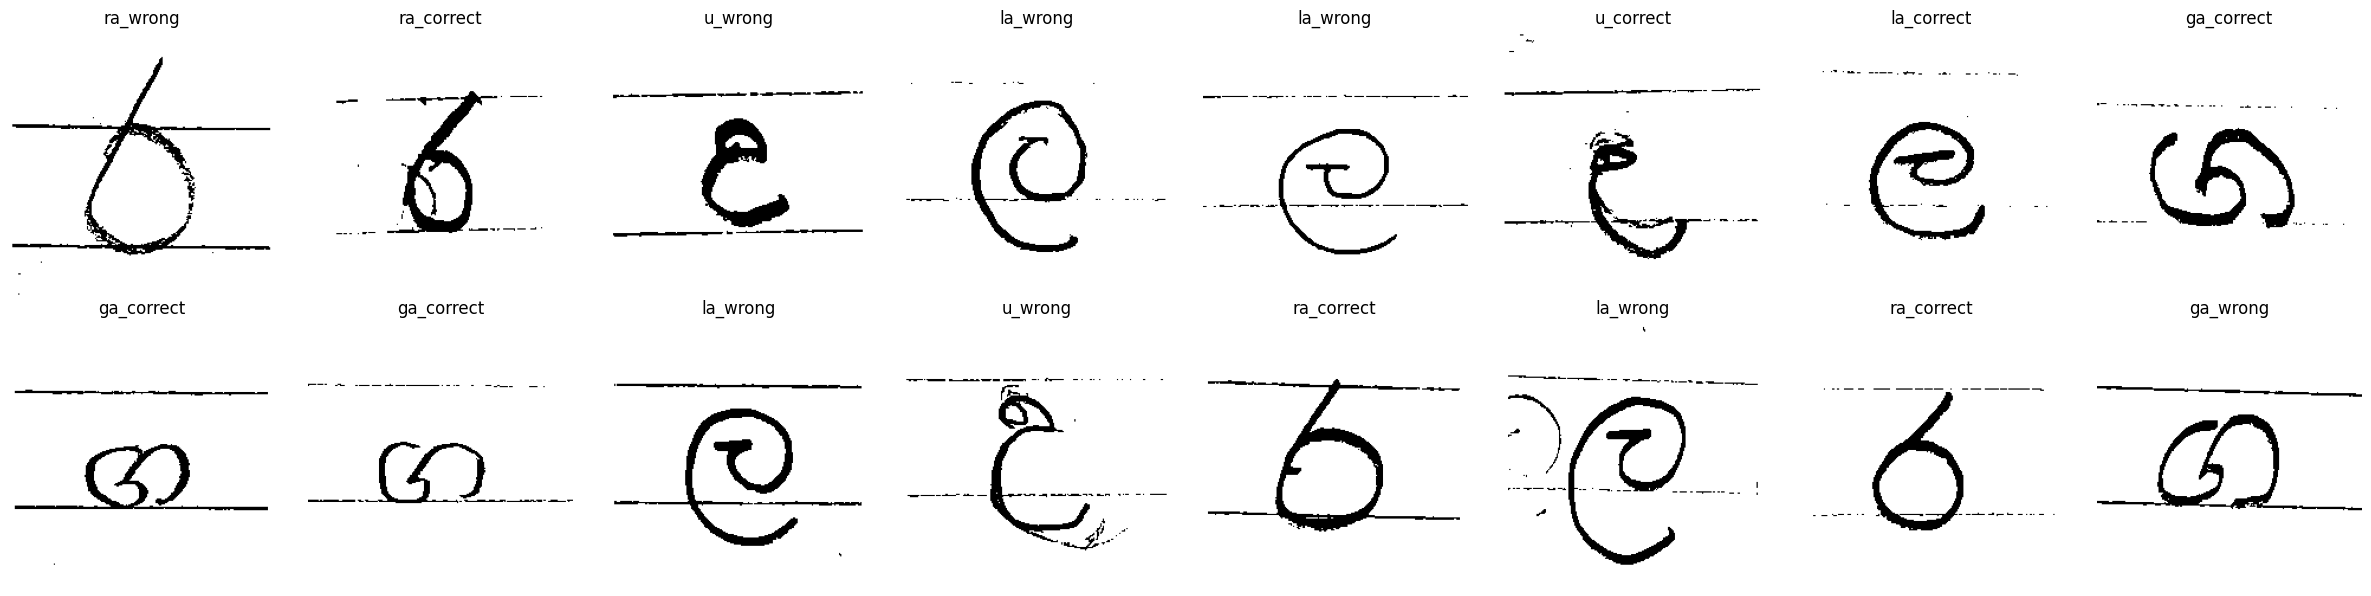

In [9]:
def show_samples(df_part, n=16):
    n = min(n, len(df_part))
    sample = df_part.sample(n, random_state=SEED)
    cols = max(n // 2, 1)
    fig, axes = plt.subplots(2, cols, figsize=(3 * cols, 6))
    for ax, (_, r) in zip(np.ravel(axes), sample.iterrows()):
        bw = load_and_binarize(r["path"]).numpy().squeeze()
        ax.imshow(bw, cmap="gray", vmin=0, vmax=255)
        ax.set_title(r["class"])
        ax.axis("off")
    plt.tight_layout()
    plt.show()

show_samples(train_df)

## 5. Build the datasets

In [10]:
train_ds = make_dataset(train_df, training=True)
val_ds   = make_dataset(val_df,   training=False)
test_ds  = make_dataset(test_df,  training=False)

# Sanity check on one batch
x, y = next(iter(train_ds))
print("Batch images :", x.shape, x.dtype)
print("Batch labels :", y.shape, y.dtype)
print(f"Value range  : {float(tf.reduce_min(x)):.1f} to {float(tf.reduce_max(x)):.1f}")

# Class weights (helps if one class has far fewer images)
from sklearn.utils.class_weight import compute_class_weight
w = compute_class_weight("balanced", classes=np.arange(NUM_CLASSES), y=train_df["label"].values)
class_weight = {i: float(w[i]) for i in range(NUM_CLASSES)}
print("Class weights:", class_weight, "| labels:", dict(enumerate(CLASS_NAMES)))

Batch images : (32, 224, 224, 3) <dtype: 'float32'>
Batch labels : (32,) <dtype: 'int32'>
Value range  : -1.0 to 1.0
Class weights: {0: 0.8848101265822785, 1: 1.1274193548387097, 2: 0.803448275862069, 3: 1.3442307692307693, 4: 1.270909090909091, 5: 0.8223529411764706, 6: 1.5195652173913043, 7: 0.7436170212765958, 8: 1.5886363636363636, 9: 0.7357894736842105} | labels: {0: 'ga_correct', 1: 'ga_wrong', 2: 'ra_correct', 3: 'ra_wrong', 4: 'ta_correct', 5: 'ta_wrong', 6: 'u_correct', 7: 'u_wrong', 8: 'la_correct', 9: 'la_wrong'}


## 6. MobileNetV2 settings

The starting values below are the best settings found for ResNet50. MobileNetV2 has **154 layers** (ResNet50 has 175), so `UNFREEZE_LAST_N = 60` fine-tunes roughly the last third of the network.
You can test other values automatically with `RUN_TUNING` in the next section.

In [11]:
from tensorflow.keras import layers, models, optimizers, callbacks, metrics

gpus = tf.config.list_physical_devices("GPU")
print("GPUs:", gpus if gpus else "NONE - switch the runtime to a T4 GPU, training on CPU is extremely slow")

# ---------------- Model / training settings ----------------
WEIGHTS          = "imagenet"   # pretrained weights
DROPOUT          = 0.6
USE_AUGMENTATION = True         # light shift/zoom only (no flips, no rotation: they can change a letter's meaning)

EPOCHS_HEAD      = 15           # stage 1 (early stopping may end it sooner)
EPOCHS_FINE      = 30           # stage 2 (early stopping may end it sooner)
LR_HEAD          = 3e-4
LR_FINE          = 1e-4
UNFREEZE_LAST_N  = 60           # how many of MobileNetV2's last layers to fine-tune in stage 2 (it has 154 layers)

GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [12]:
def build_mobilenetv2(input_shape=(IMG_HEIGHT, IMG_WIDTH, 3), dropout=None, augment=None):
    dropout = DROPOUT if dropout is None else dropout
    augment = USE_AUGMENTATION if augment is None else augment

    # include_top=False removes the 1000-class ImageNet classifier, we add our own head
    base = tf.keras.applications.MobileNetV2(
        include_top=False, weights=WEIGHTS, input_shape=input_shape)
    base.trainable = False                       # stage 1: backbone frozen

    inputs = layers.Input(shape=input_shape, name="image")   # already MobileNetV2-preprocessed by the data pipeline
    x = inputs
    if augment:
        x = layers.RandomTranslation(0.05, 0.05, fill_mode="nearest")(x)
        x = layers.RandomZoom(0.05, fill_mode="nearest")(x)

    x = base(x, training=False)                  # keeps BatchNorm in inference mode (important for fine-tuning)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(dropout)(x)
    outputs = layers.Dense(NUM_CLASSES, activation="softmax", name="class_probs")(x)

    model = models.Model(inputs, outputs, name="mobilenetv2_letter_10class")
    return model, base


def compile_model(model, lr):
    model.compile(
        optimizer=optimizers.Adam(learning_rate=lr),
        loss="sparse_categorical_crossentropy",   # labels are integers 0..9
        metrics=["accuracy"],
    )


def make_callbacks(stage):
    return [
        callbacks.ModelCheckpoint(
            str(CHECKPOINT_DIR / f"mobilenetv2_{stage}_best.keras"),
            monitor="val_loss", save_best_only=True, verbose=1),
        callbacks.EarlyStopping(
            monitor="val_loss", patience=5, restore_best_weights=True, verbose=1),
        callbacks.ReduceLROnPlateau(
            monitor="val_loss", factor=0.3, patience=2, min_lr=1e-7, verbose=1),
    ]


def count_params(model):
    trainable = int(sum(np.prod(v.shape) for v in model.trainable_weights))
    total = int(model.count_params())
    return trainable, total


class TestCurve(callbacks.Callback):
    '''Scores the TEST set after every epoch, ONLY to draw the test curve.
    It never changes training: early stopping, checkpoints and the learning rate use validation only.'''
    def __init__(self, ds):
        super().__init__()
        self.ds = ds
        self.loss, self.acc = [], []

    def on_epoch_end(self, epoch, logs=None):
        total_loss, correct, n = 0.0, 0, 0
        for x, y in self.ds:
            p = np.asarray(self.model.predict_on_batch(x))
            y = y.numpy()
            total_loss += float(-np.log(np.clip(p[np.arange(len(y)), y], 1e-7, 1.0)).sum())
            correct += int((p.argmax(axis=1) == y).sum())
            n += len(y)
        self.loss.append(total_loss / n)
        self.acc.append(correct / n)


## 7. Optional: automatic tuning (off by default)

Set `RUN_TUNING = True` to test several settings (dropout, learning rate, how many layers to fine-tune) on the **validation** set. It takes about 30-40 minutes.
Trial 0 is always your current settings. The best settings are used automatically **only if they beat trial 0 by at least 3 points** of macro F1 (smaller differences are just luck with 150 validation images).
The test set is not used here.

In [13]:
import itertools, random
from IPython.display import display
from sklearn.metrics import accuracy_score, f1_score, recall_score

RUN_TUNING       = False    # True = run the search now (30-40 min)
N_TRIALS         = 8        # trial 0 = your current settings
TUNE_EPOCHS_HEAD = 8
TUNE_EPOCHS_FINE = 20

SPACE = {
    "dropout":  [0.5, 0.6, 0.7],
    "lr_head":  [3e-4],
    "lr_fine":  [3e-5, 1e-4, 3e-4],
    "unfreeze": [30, 60, 100, 154],        # 154 = fine-tune the whole MobileNetV2
    "augment":  [True],
}
BASELINE = {"dropout": DROPOUT, "lr_head": LR_HEAD, "lr_fine": LR_FINE,
            "unfreeze": UNFREEZE_LAST_N, "augment": USE_AUGMENTATION}


def evaluate_on_val(model_t):
    '''Scores a trial model on the VALIDATION set only.'''
    y_all, p_all = [], []
    for x, y in val_ds:
        p_all.append(np.asarray(model_t.predict_on_batch(x)))
        y_all.append(y.numpy())
    y_val, probs = np.concatenate(y_all), np.concatenate(p_all)
    y_pred = probs.argmax(axis=1)
    all_labels = list(range(NUM_CLASSES))
    recalls = recall_score(y_val, y_pred, labels=all_labels, average=None, zero_division=0)
    app_says_correct = (y_pred == (y_val // 2) * 2)          # the app asks for the letter the student wrote
    truth_is_correct = (y_val % 2 == 0)
    return {
        "val_acc":            float(accuracy_score(y_val, y_pred)),
        "val_macro_f1":       float(f1_score(y_val, y_pred, labels=all_labels, average="macro", zero_division=0)),
        "worst_class":        CLASS_NAMES[int(recalls.argmin())],
        "worst_class_recall": float(recalls.min()),
        "val_app_acc":        float(accuracy_score(truth_is_correct, app_says_correct)),
    }


def run_trial(cfg):
    tf.keras.backend.clear_session()
    gc.collect()
    tf.keras.utils.set_random_seed(SEED)           # same starting point for every trial = fair comparison
    model_t, base_t = build_mobilenetv2(dropout=cfg["dropout"], augment=cfg["augment"])

    def quick_callbacks():                          # no checkpoint saving: your real model files are not touched
        return [callbacks.EarlyStopping(monitor="val_loss", patience=4, restore_best_weights=True),
                callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.3, patience=2, min_lr=1e-7)]

    compile_model(model_t, cfg["lr_head"])
    model_t.fit(train_ds, validation_data=val_ds, epochs=TUNE_EPOCHS_HEAD,
                class_weight=class_weight, callbacks=quick_callbacks(), verbose=0)

    base_t.trainable = True
    for layer in base_t.layers[:-cfg["unfreeze"]]:
        layer.trainable = False
    for layer in base_t.layers:
        if isinstance(layer, layers.BatchNormalization):
            layer.trainable = False
    compile_model(model_t, cfg["lr_fine"])
    hist = model_t.fit(train_ds, validation_data=val_ds, epochs=TUNE_EPOCHS_FINE,
                       class_weight=class_weight, callbacks=quick_callbacks(), verbose=0)

    row = {"val_loss": float(min(hist.history["val_loss"])),
           "train_acc": float(model_t.evaluate(train_ds, verbose=0, return_dict=True)["accuracy"])}
    row.update(evaluate_on_val(model_t))
    return row


rows = []
if RUN_TUNING:
    grid = [dict(zip(SPACE, values)) for values in itertools.product(*SPACE.values())]
    grid = [c for c in grid if c != BASELINE]
    random.Random(SEED).shuffle(grid)
    configs = [BASELINE] + grid[: max(N_TRIALS - 1, 0)]
    print(f"Will run {len(configs)} trials")
    t_start = time.time()
    for i, cfg in enumerate(configs):
        t0 = time.time()
        try:
            row = {"trial": i, **cfg, **run_trial(cfg)}
            rows.append(row)
            print(f"[{i + 1}/{len(configs)}] {cfg}\n      val acc {row['val_acc']:.3f} | macro F1 {row['val_macro_f1']:.3f} | "
                  f"worst class {row['worst_class']} ({row['worst_class_recall']:.2f}) | {time.time() - t0:.0f}s")
        except Exception as e:                       # one failed trial should not stop the whole search
            print(f"[{i + 1}/{len(configs)}] FAILED {cfg}: {type(e).__name__}: {e}")
    tf.keras.backend.clear_session()
    print(f"\nTotal time: {(time.time() - t_start) / 60:.1f} minutes")
else:
    print("Tuning skipped (RUN_TUNING = False). The settings from the settings cell are used.")

Tuning skipped (RUN_TUNING = False). The settings from the settings cell are used.


In [14]:
if RUN_TUNING and rows:
    res = pd.DataFrame(rows).sort_values(["val_macro_f1", "val_loss"], ascending=[False, True]).reset_index(drop=True)
    show_cols = ["trial", "dropout", "lr_head", "lr_fine", "unfreeze", "augment", "train_acc", "val_acc",
                 "val_macro_f1", "val_app_acc", "worst_class", "worst_class_recall", "val_loss"]
    display(res[show_cols].round(4))
    res.to_csv(METRICS_DIR / "mobilenetv2_tuning_results.csv", index=False)

    best = res.iloc[0]
    gain = best["val_macro_f1"] - float(res.loc[res["trial"] == 0, "val_macro_f1"].iloc[0])
    print(f"\nBest vs your current settings: macro F1 {gain:+.3f}")
    if gain >= 0.03:
        DROPOUT          = float(best["dropout"])
        USE_AUGMENTATION = bool(best["augment"])
        LR_HEAD          = float(best["lr_head"])
        LR_FINE          = float(best["lr_fine"])
        UNFREEZE_LAST_N  = int(best["unfreeze"])
        print("Using the best settings:", dict(DROPOUT=DROPOUT, USE_AUGMENTATION=USE_AUGMENTATION,
              LR_HEAD=LR_HEAD, LR_FINE=LR_FINE, UNFREEZE_LAST_N=UNFREEZE_LAST_N))
    else:
        print("The difference is small (probably just luck), so the current settings are kept.")
else:
    print("No tuning results to show.")

No tuning results to show.


## 8. Build the model

In [15]:
model, base = build_mobilenetv2()
compile_model(model, LR_HEAD)

trainable, total = count_params(model)
print(f"Settings: dropout={DROPOUT}, augmentation={USE_AUGMENTATION}, lr_head={LR_HEAD}, lr_fine={LR_FINE}, unfreeze_last={UNFREEZE_LAST_N}")
print(f"MobileNetV2 layers: {len(base.layers)}")
print(f"Stage 1 | trainable params: {trainable:,} of {total:,}")
print("Output classes:", dict(enumerate(CLASS_NAMES)))
model.summary(show_trainable=True)

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
Settings: dropout=0.6, augmentation=True, lr_head=0.0003, lr_fine=0.0001, unfreeze_last=60
MobileNetV2 layers: 154
Stage 1 | trainable params: 12,810 of 2,270,794
Output classes: {0: 'ga_correct', 1: 'ga_wrong', 2: 'ra_correct', 3: 'ra_wrong', 4: 'ta_correct', 5: 'ta_wrong', 6: 'u_correct', 7: 'u_wrong', 8: 'la_correct', 9: 'la_wrong'}


Model: "mobilenetv2_letter_10class"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━┓
┃ Layer (type)                ┃ Output Shape          ┃    Param # ┃ Trai… ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━┩
│ image (InputLayer)          │ (None, 224, 224, 3)   │          0 │   -   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ random_translation          │ (None, 224, 224, 3)   │          0 │   -   │
│ (RandomTranslation)         │                       │            │       │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ random_zoom (RandomZoom)    │ (None, 224, 224, 3)   │          0 │   -   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ mobilenetv2_1.00_224        │ (None, 7, 7, 1280)    │  2,257,984 │   N   │
│ (Functional)                │                       │            │       │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ global_average_pooling2d    │ (None, 1280)          │          0 │   -   │
│ (GlobalAveragePooling2D)    │                       │            │       │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ dropout (Dropout)           │ (None, 1280)          │          0 │   -   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ class_probs (Dense)         │ (None, 10)            │     12,810 │   Y   │
└─────────────────────────────┴───────────────────────┴────────────┴───────┘

 Total params: 2,270,794 (8.66 MB)

 Trainable params: 12,810 (50.04 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

## 9. Stage 1 - train the classifier head (MobileNetV2 frozen)

In [16]:
test_curve_head = TestCurve(test_ds)      # test line for the curve (display only)

history_head = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS_HEAD,
    class_weight=class_weight,
    callbacks=make_callbacks("head") + [test_curve_head],
)

Epoch 1/15
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 59ms/step - accuracy: 0.1349 - loss: 3.3386
Epoch 1: val_loss improved from None to 2.44332, saving model to /content/drive/MyDrive/dataset/models_10class/checkpoints/mobilenetv2_head_best.keras

Epoch 1: finished saving model to /content/drive/MyDrive/dataset/models_10class/checkpoints/mobilenetv2_head_best.keras
22/22 ━━━━━━━━━━━━━━━━━━━━ 18s 466ms/step - accuracy: 0.1087 - loss: 3.2541 - val_accuracy: 0.1067 - val_loss: 2.4433 - learning_rate: 3.0000e-04
Epoch 2/15
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 55ms/step - accuracy: 0.1549 - loss: 2.9203
Epoch 2: val_loss improved from 2.44332 to 2.17388, saving model to /content/drive/MyDrive/dataset/models_10class/checkpoints/mobilenetv2_head_best.keras

Epoch 2: finished saving model to /content/drive/MyDrive/dataset/models_10class/checkpoints/mobilenetv2_head_best.keras
22/22 ━━━━━━━━━━━━━━━━━━━━ 2s 110ms/step - accuracy: 0.1474 - loss: 2.9359 - val_accuracy: 0.1933 - val_loss: 2.1739 - learning_rate: 3.0

## 10. Stage 2 - fine-tune the last MobileNetV2 layers

Only the last `UNFREEZE_LAST_N` layers are unfrozen. BatchNorm layers stay frozen, and the learning rate is smaller so the pretrained features are adjusted gently instead of destroyed.

In [17]:
base.trainable = True
for layer in base.layers[:-UNFREEZE_LAST_N]:
    layer.trainable = False
for layer in base.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

compile_model(model, LR_FINE)          # must re-compile after changing trainable flags

trainable, total = count_params(model)
print(f"Stage 2 | trainable params: {trainable:,} of {total:,}")

test_curve_fine = TestCurve(test_ds)      # test line for the curve (display only)

history_fine = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS_FINE,
    class_weight=class_weight,
    callbacks=make_callbacks("finetune") + [test_curve_fine],
)

Stage 2 | trainable params: 1,944,586 of 2,270,794
Epoch 1/30
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 78ms/step - accuracy: 0.3918 - loss: 1.8064
Epoch 1: val_loss improved from None to 1.00849, saving model to /content/drive/MyDrive/dataset/models_10class/checkpoints/mobilenetv2_finetune_best.keras

Epoch 1: finished saving model to /content/drive/MyDrive/dataset/models_10class/checkpoints/mobilenetv2_finetune_best.keras
22/22 ━━━━━━━━━━━━━━━━━━━━ 13s 308ms/step - accuracy: 0.4092 - loss: 1.5867 - val_accuracy: 0.5800 - val_loss: 1.0085 - learning_rate: 1.0000e-04
Epoch 2/30
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 73ms/step - accuracy: 0.5825 - loss: 1.0127
Epoch 2: val_loss improved from 1.00849 to 0.79891, saving model to /content/drive/MyDrive/dataset/models_10class/checkpoints/mobilenetv2_finetune_best.keras

Epoch 2: finished saving model to /content/drive/MyDrive/dataset/models_10class/checkpoints/mobilenetv2_finetune_best.keras
22/22 ━━━━━━━━━━━━━━━━━━━━ 3s 132ms/step - accuracy: 0.5694 - loss: 0.

## 11. Training curves (train, validation and TEST) + save the model

The **test** line is only for the picture. The model is still chosen by validation.

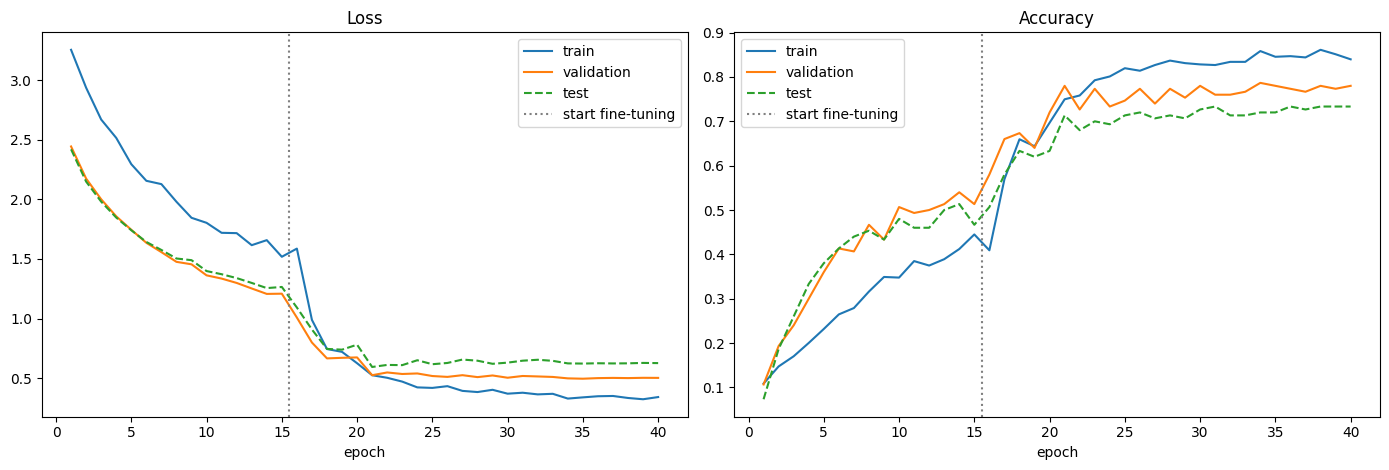

Best validation loss 0.4955 at epoch 35 (finetune) | val acc 0.7800
The test line is for the picture only. Report the numbers from the evaluation section below.


In [18]:
# Join both stages into one history
history_all = {k: history_head.history[k] + history_fine.history[k] for k in history_head.history}
hist_df = pd.DataFrame(history_all)
hist_df.insert(0, "epoch", range(1, len(hist_df) + 1))
hist_df.insert(1, "stage", ["head"] * len(history_head.history["loss"]) + ["finetune"] * len(history_fine.history["loss"]))

# Test curve (display only)
hist_df["test_loss"]     = test_curve_head.loss + test_curve_fine.loss
hist_df["test_accuracy"] = test_curve_head.acc  + test_curve_fine.acc
hist_df.to_csv(METRICS_DIR / "mobilenetv2_training_history.csv", index=False)

split_at = len(history_head.history["loss"]) + 0.5      # boundary between stage 1 and stage 2
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
for ax, (key, title) in zip(axes, [("loss", "Loss"), ("accuracy", "Accuracy")]):
    ax.plot(hist_df["epoch"], hist_df[key], label="train")
    ax.plot(hist_df["epoch"], hist_df[f"val_{key}"], label="validation")
    ax.plot(hist_df["epoch"], hist_df[f"test_{key}"], label="test", linestyle="--")
    ax.axvline(split_at, color="gray", linestyle=":", label="start fine-tuning")
    ax.set_title(title); ax.set_xlabel("epoch"); ax.legend()
plt.tight_layout()
plt.savefig(PLOTS_DIR / "mobilenetv2_training_curves.png", dpi=150)
plt.show()

best_row = hist_df.loc[hist_df["val_loss"].idxmin()]
print(f"Best validation loss {best_row['val_loss']:.4f} at epoch {int(best_row['epoch'])} "
      f"({best_row['stage']}) | val acc {best_row['val_accuracy']:.4f}")
print("The test line is for the picture only. Report the numbers from the evaluation section below.")

In [19]:
# Full model (with training state) and a light copy for the backend (same predictions, smaller file)
full_path  = FINAL_MODEL_DIR / "mobilenetv2_letter_10class.keras"
light_path = FINAL_MODEL_DIR / "mobilenetv2_letter_10class_light.keras"
model.save(full_path)
tf.keras.models.load_model(full_path, compile=False).save(light_path)
print("Saved:", full_path.name, f"{full_path.stat().st_size / 1e6:.0f} MB |", light_path.name, f"{light_path.stat().st_size / 1e6:.0f} MB")

# Save the class order: the app needs this exact list to turn model outputs into names
with open(FINAL_MODEL_DIR / "class_names.json", "w") as f:
    json.dump(CLASS_NAMES, f)

Saved: mobilenetv2_letter_10class.keras 25 MB | mobilenetv2_letter_10class_light.keras 10 MB


## 12. Model evaluation

Same evaluation as the ResNet50 notebook. Look at the **test** row, and at Test 1 / Test 2:
- **Test 1:** the student writes the asked letter. How often is the app's Correct/Wrong answer right?
- **Test 2:** the student writes a different letter. The app must say Wrong (this number should be close to 0%).

In [20]:
from IPython.display import display
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, f1_score,
    confusion_matrix, classification_report, ConfusionMatrixDisplay,
)

def predict_dataset(ds):
    """Returns (true labels, probability matrix [N, 10]) in dataset order."""
    labels, probs = [], []
    for x, y in ds:
        probs.append(np.asarray(model.predict_on_batch(x)))
        labels.append(y.numpy())
    return np.concatenate(labels), np.concatenate(probs)

# class id -> letter id / correct-or-wrong, so we can score the "real app" decision
LETTER_OF  = np.array([i // 2 for i in range(NUM_CLASSES)])      # 0..4
IS_CORRECT = np.array([i % 2 == 0 for i in range(NUM_CLASSES)])  # even ids are *_correct

def compute_metrics(y_true, probs):
    y_pred = probs.argmax(axis=1)
    # What the app really needs, split in two questions:
    letter_acc = accuracy_score(LETTER_OF[y_true], LETTER_OF[y_pred])        # right letter identified?
    quality_acc = accuracy_score(IS_CORRECT[y_true], IS_CORRECT[y_pred])     # correct/wrong judged right?
    return {
        "samples":           int(len(y_true)),
        "accuracy_10class":  float(accuracy_score(y_true, y_pred)),
        "balanced_accuracy": float(balanced_accuracy_score(y_true, y_pred)),
        "f1_macro":          float(f1_score(y_true, y_pred, average="macro", zero_division=0)),
        "letter_accuracy":   float(letter_acc),
        "correct_wrong_accuracy": float(quality_acc),
    }

### Train vs validation vs test

If train is much better than validation/test, the model is overfitting.

In [21]:
raw, results = {}, {}
for name, ds in [("train", train_ds), ("val", val_ds), ("test", test_ds)]:
    y_t, p = predict_dataset(ds)
    raw[name] = (y_t, p)
    results[name] = compute_metrics(y_t, p)

summary = pd.DataFrame(results).T
summary["samples"] = summary["samples"].astype(int)
display(summary.round(4))
summary.to_csv(METRICS_DIR / "mobilenetv2_10class_metrics_all_splits.csv")

,samples,accuracy_10class,balanced_accuracy,f1_macro,letter_accuracy,correct_wrong_accuracy
train,699,0.8727,0.8546,0.8618,1.0000,0.8727
val,150,0.7800,0.7592,0.7600,0.9933,0.7867
test,150,0.7200,0.7120,0.7006,1.0000,0.7200


### Test set: full classification report

In [22]:
y_true, probs = raw["test"]
y_pred = probs.argmax(axis=1)

print(classification_report(y_true, y_pred, labels=list(range(NUM_CLASSES)),
                            target_names=CLASS_NAMES, digits=3, zero_division=0))
m = results["test"]
for k, v in m.items():
    print(f"{k:<24}: {v}")

              precision    recall  f1-score   support

  ga_correct      0.667     0.353     0.462        17
    ga_wrong      0.476     0.769     0.588        13
  ra_correct      0.810     0.895     0.850        19
    ra_wrong      0.778     0.636     0.700        11
  ta_correct      0.550     0.917     0.688        12
    ta_wrong      0.900     0.500     0.643        18
   u_correct      0.778     0.700     0.737        10
     u_wrong      0.857     0.900     0.878        20
  la_correct      0.667     0.600     0.632        10
    la_wrong      0.810     0.850     0.829        20

    accuracy                          0.720       150
   macro avg      0.729     0.712     0.701       150
weighted avg      0.747     0.720     0.713       150

samples                 : 150
accuracy_10class        : 0.72
balanced_accuracy       : 0.7119939090836922
f1_macro                : 0.7005869024315562
letter_accuracy         : 1.0
correct_wrong_accuracy  : 0.72


### Confusion matrix

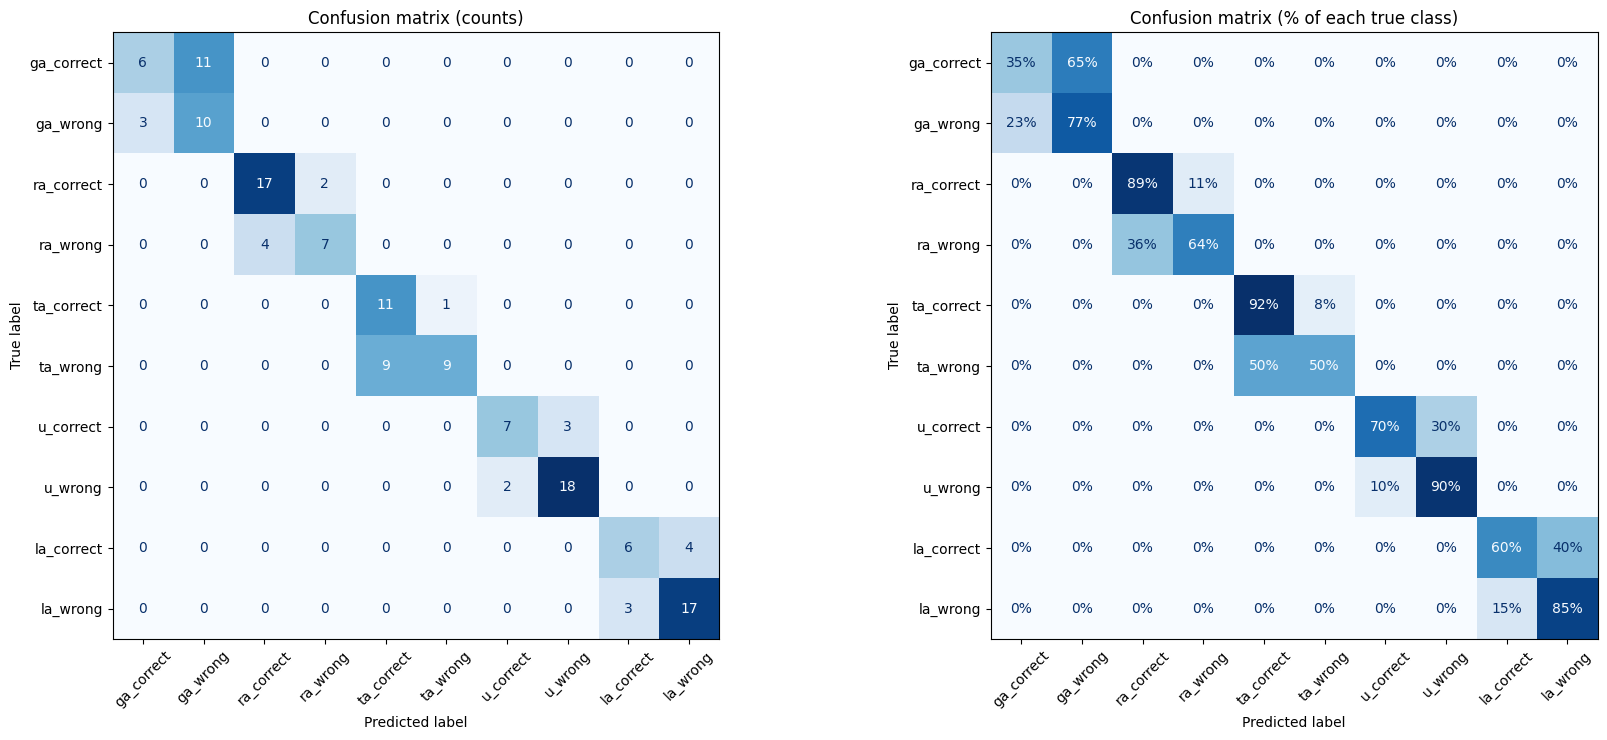

In [23]:
cm      = confusion_matrix(y_true, y_pred, labels=list(range(NUM_CLASSES)))
cm_norm = confusion_matrix(y_true, y_pred, labels=list(range(NUM_CLASSES)), normalize="true")

fig, ax = plt.subplots(1, 2, figsize=(18, 7.5))
ConfusionMatrixDisplay(cm, display_labels=CLASS_NAMES).plot(ax=ax[0], cmap="Blues", colorbar=False, xticks_rotation=45)
ax[0].set_title("Confusion matrix (counts)")
ConfusionMatrixDisplay(cm_norm, display_labels=CLASS_NAMES).plot(
    ax=ax[1], cmap="Blues", colorbar=False, values_format=".0%", xticks_rotation=45)
ax[1].set_title("Confusion matrix (% of each true class)")
plt.tight_layout()
plt.savefig(PLOTS_DIR / "mobilenetv2_10class_confusion_matrix.png", dpi=150)
plt.show()

### The real app scenario

In [24]:
# ---------- The real app scenario ----------
# The app ASKS for a letter. Answer is "Correct" only if the model predicts "<asked>_correct".
def app_decision(probs_row, asked_letter_id):
    return int(probs_row.argmax() == asked_letter_id * 2)     # 1 = app says Correct

# Test 1: student writes the ASKED letter (the normal case)
true_letter = LETTER_OF[y_true]
app_says = np.array([app_decision(p, l) for p, l in zip(probs, true_letter)])
should_be = IS_CORRECT[y_true].astype(int)
print(f"Test 1 - student writes the asked letter: app is right {np.mean(app_says == should_be):.1%} of the time")

# Test 2: student writes a DIFFERENT letter than asked (always must be Wrong)
fooled, total = 0, 0
for p, l in zip(probs, true_letter):
    for asked in range(len(LETTERS)):
        if asked == l:
            continue
        total += 1
        fooled += app_decision(p, asked)          # app wrongly says Correct
print(f"Test 2 - student writes another letter: app wrongly says Correct {fooled/total:.1%} of the time "
      f"({fooled} of {total})")

Test 1 - student writes the asked letter: app is right 72.0% of the time
Test 2 - student writes another letter: app wrongly says Correct 0.0% of the time (0 of 600)


### Confidence: how sure is the model when it is right vs wrong?

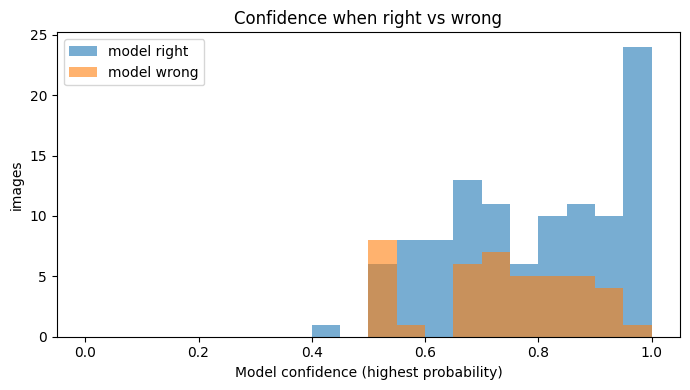

confidence >= 0.4: answered 100% of images, accuracy on those 72.0%
confidence >= 0.5: answered 99% of images, accuracy on those 71.8%
confidence >= 0.6: answered 84% of images, accuracy on those 73.8%
confidence >= 0.7: answered 66% of images, accuracy on those 72.7%
confidence >= 0.8: answered 47% of images, accuracy on those 78.6%


In [25]:
# Confidence: how sure is the model when it is right vs wrong? Use this to choose a "try again" limit.
conf = probs.max(axis=1)
right = (y_pred == y_true)

plt.figure(figsize=(7, 4))
plt.hist(conf[right],  bins=20, range=(0, 1), alpha=0.6, label="model right")
plt.hist(conf[~right], bins=20, range=(0, 1), alpha=0.6, label="model wrong")
plt.xlabel("Model confidence (highest probability)"); plt.ylabel("images"); plt.legend()
plt.title("Confidence when right vs wrong")
plt.tight_layout()
plt.savefig(PLOTS_DIR / "mobilenetv2_10class_confidence.png", dpi=150)
plt.show()

for t in [0.4, 0.5, 0.6, 0.7, 0.8]:
    keep = conf >= t
    print(f"confidence >= {t:.1f}: answered {keep.mean():.0%} of images, accuracy on those {right[keep].mean():.1%}")

### Misclassified test images (most confident mistakes first)

Misclassified test images: 42 of 150


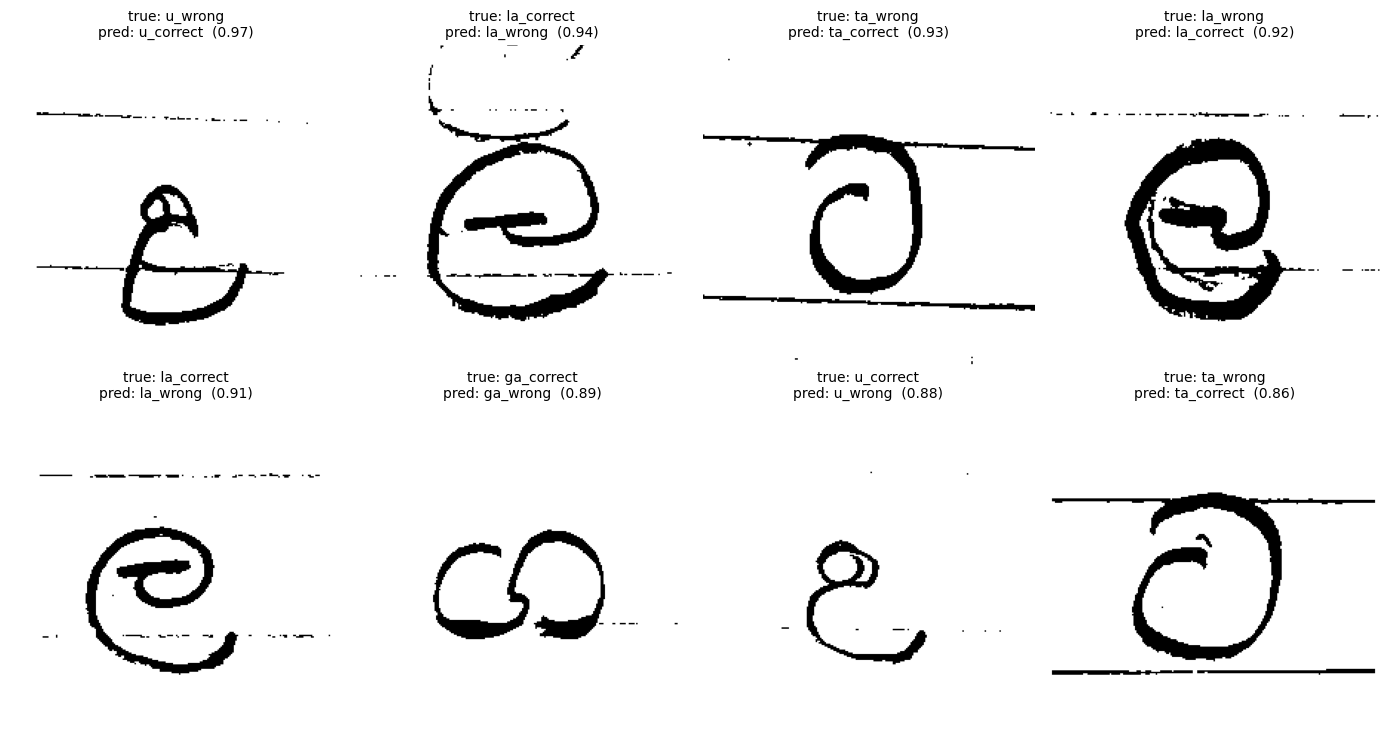

In [26]:
assert np.array_equal(y_true, test_df["label"].values), "test_ds order does not match test_df"

wrong_idx = np.where(y_pred != y_true)[0]
print(f"Misclassified test images: {len(wrong_idx)} of {len(y_true)}")

if len(wrong_idx):
    err_conf = probs[wrong_idx, y_pred[wrong_idx]]          # most confident mistakes first
    wrong_idx = wrong_idx[np.argsort(-err_conf)]
    show = wrong_idx[:8]

    fig, axes = plt.subplots(2, 4, figsize=(14, 7.5))
    for ax in axes.ravel():
        ax.axis("off")
    for ax, i in zip(axes.ravel(), show):
        bw = load_and_binarize(test_df.iloc[i]["path"]).numpy().squeeze()
        ax.imshow(bw, cmap="gray", vmin=0, vmax=255)
        ax.set_title(f"true: {CLASS_NAMES[y_true[i]]}\npred: {CLASS_NAMES[y_pred[i]]}  ({probs[i, y_pred[i]]:.2f})",
                     fontsize=10)
    plt.tight_layout()
    plt.savefig(PLOTS_DIR / "mobilenetv2_10class_misclassified.png", dpi=150)
    plt.show()

### Save the evaluation results and predictions

In [27]:
with open(METRICS_DIR / "mobilenetv2_10class_test_metrics.json", "w") as f:
    json.dump({"test": results["test"], "class_names": CLASS_NAMES}, f, indent=2)

pred_df = test_df.drop(columns=["md5"], errors="ignore").copy()
for i, c in enumerate(CLASS_NAMES):
    pred_df["prob_" + c] = probs[:, i]
pred_df["pred_label"] = y_pred
pred_df["pred_class"] = [CLASS_NAMES[i] for i in y_pred]
pred_df["is_correct"] = (y_pred == y_true)
pred_df.to_csv(METRICS_DIR / "mobilenetv2_10class_test_predictions.csv", index=False)
print("Saved to", METRICS_DIR)

Saved to /content/drive/MyDrive/dataset/results_10class/metrics


## 13. Compare all models you trained

This reads every `*_10class_test_predictions.csv` file in your metrics folder (ResNet50, this MobileNetV2, and any model you train later with the same notebook style) and puts the results side by side.
The models are only comparable if they were tested on the **same test images**. A warning is printed if not.

In [28]:
def summarize_predictions(csv_path):
    d = pd.read_csv(csv_path)
    P = d[[f"prob_{c}" for c in CLASS_NAMES]].values
    yt = d["label"].values
    yp = P.argmax(axis=1)
    tl = LETTER_OF[yt]

    # Test 1: the app asks for the letter the student really wrote
    app_says = np.array([int(p.argmax() == l * 2) for p, l in zip(P, tl)])
    test1 = float((app_says == IS_CORRECT[yt].astype(int)).mean())
    # Test 2: the app asks for a different letter -> must say Wrong
    fooled = total = 0
    for p, l in zip(P, tl):
        for asked in range(len(LETTERS)):
            if asked != l:
                total += 1
                fooled += int(p.argmax() == asked * 2)

    rec = recall_score(yt, yp, labels=list(range(NUM_CLASSES)), average=None, zero_division=0)
    summary = {
        "test_images":            int(len(d)),
        "acc_10class":            float(accuracy_score(yt, yp)),
        "macro_f1":               float(f1_score(yt, yp, labels=list(range(NUM_CLASSES)), average="macro", zero_division=0)),
        "letter_acc":             float(accuracy_score(tl, LETTER_OF[yp])),
        "correct_wrong_acc":      float(accuracy_score(IS_CORRECT[yt], IS_CORRECT[yp])),
        "app_acc (Test 1)":       test1,
        "other_letter_accepted (Test 2)": float(fooled / total),
        "worst_class":            CLASS_NAMES[int(rec.argmin())],
        "worst_class_recall":     float(rec.min()),
    }
    return summary, rec, set(d["path"])


files_found = sorted(METRICS_DIR.glob("*_10class_test_predictions.csv"))
if len(files_found) < 2:
    print("Only", len(files_found), "model result file found. Train and evaluate another model to compare.")
else:
    summaries, recalls, test_sets = {}, {}, {}
    for f in files_found:
        name = f.name.replace("_10class_test_predictions.csv", "")
        summaries[name], recalls[name], test_sets[name] = summarize_predictions(f)

    if len({frozenset(s) for s in test_sets.values()}) > 1:
        print("WARNING: these models were NOT tested on the same images, so the comparison is not fair.\n")

    comparison = pd.DataFrame(summaries).T
    display(comparison.round(4))
    print("\nHow much of each class is found (recall):")
    per_class = pd.DataFrame(recalls, index=CLASS_NAMES)
    display(per_class.round(2))
    comparison.to_csv(METRICS_DIR / "model_comparison.csv")
    per_class.to_csv(METRICS_DIR / "model_comparison_per_class_recall.csv")
    print("\nDifferences smaller than about 3 points are probably just luck with a test set this small.")

,test_images,acc_10class,macro_f1,letter_acc,correct_wrong_acc,app_acc (Test 1),other_letter_accepted (Test 2),worst_class,worst_class_recall
densenet121,150,0.633333,0.611425,0.98,0.653333,0.653333,0.0,ga_wrong,0.230769
mobilenetv2,150,0.72,0.700587,1.0,0.72,0.72,0.0,ga_correct,0.352941
resnet50,150,0.786667,0.777032,1.0,0.786667,0.786667,0.0,ga_wrong,0.615385



How much of each class is found (recall):


,densenet121,mobilenetv2,resnet50
ga_correct,0.59,0.35,0.76
ga_wrong,0.23,0.77,0.62
ra_correct,0.68,0.89,0.68
ra_wrong,0.64,0.64,0.91
ta_correct,0.67,0.92,0.83
ta_wrong,0.33,0.50,0.72
u_correct,1.00,0.70,0.70
u_wrong,0.80,0.90,0.85
la_correct,0.50,0.60,0.90
la_wrong,0.85,0.85,0.90



Differences smaller than about 3 points are probably just luck with a test set this small.


## 14. Download the trained model

In [29]:
from google.colab import files
files.download(str(FINAL_MODEL_DIR / "mobilenetv2_letter_10class_light.keras"))   # smaller file, same predictions
files.download(str(FINAL_MODEL_DIR / "class_names.json"))

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [30]:
# ================= APP-SIDE LOGIC =================
# Use this function inside your app. It needs: the image path and the letter the app asked for.
MIN_CONFIDENCE = 0.5      # below this the model is unsure -> ask the student to try again

def check_letter(image_path, asked_letter):
    """asked_letter: one of 'ga','ra','ta','u','la'. Returns (verdict, details)."""
    bw = load_and_binarize(image_path)
    x, _ = to_model_input(bw, 0)
    probs = model.predict(x[None, ...], verbose=0)[0]

    best = int(probs.argmax())
    pred_class = CLASS_NAMES[best]
    confidence = float(probs[best])
    pred_letter, pred_state = pred_class.split("_")

    if confidence < MIN_CONFIDENCE:
        verdict = "Try again"
    elif pred_letter != asked_letter:
        verdict = "Wrong"          # a different letter was written
    elif pred_state == "correct":
        verdict = "Correct"
    else:
        verdict = "Wrong"          # right letter, written badly
    return verdict, {"model_saw": pred_class, "confidence": round(confidence, 3)}

# Example (change the path):
# print(check_letter(test_df.iloc[0]["path"], "ga"))